# 01 · Exploratory data analysis

Dataset for the CAG + RAG chatbot:

- `policy_handbook.md`: 32 bank policies (the CAG source)
- `cases.jsonl`: 5,000 customer-service cases (the RAG and analytics source)

The goal is to understand what's in the data and which properties shape the pipeline design: what to cache, what to embed, what to filter on, and what to count with SQL.

## 0. Setup

In [1]:
import json
import re
from itertools import combinations
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
import tiktoken

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CASES_PATH = ROOT / "cases.jsonl"
HANDBOOK_PATH = ROOT / "policy_handbook.md"

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Chart style: thin marks, recessive grid, one hue unless a chart compares groups
SURFACE = "#fcfcfb"
BLUE, LIGHT_BLUE, ORANGE, RED = "#2a78d6", "#86b6ef", "#eb6834", "#e34948"
GRAY, INK, INK2, MUTED, GRID = "#c3c2b7", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
OUTCOME_ORDER = ["favorable", "partial", "info", "unfavorable"]
OUTCOME_COLORS = {"favorable": BLUE, "partial": LIGHT_BLUE, "info": GRAY, "unfavorable": RED}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "axes.titlesize": 12,
    "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10, "legend.frameon": False,
})


def barh(series, title, xlabel="cases", color=BLUE, ax=None, fmt="{:,.0f}"):
    """Sorted horizontal bar chart with value labels at the bar ends."""
    s = series.sort_values()
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.3 * len(s) + 0.9))
    ax.barh(s.index.astype(str), s.values, color=color, height=0.72, edgecolor=SURFACE, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    for y, v in enumerate(s.values):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8.5, color=INK2)
    ax.margins(x=0.12)
    return ax


enc = tiktoken.get_encoding("cl100k_base")  # approximation; local models tokenize a bit differently
n_tokens = lambda s: len(enc.encode(s))

## 1. Load and check data quality

In [2]:
df = pd.DataFrame([json.loads(line) for line in CASES_PATH.open(encoding="utf-8")])
df["opened_date"] = pd.to_datetime(df["opened_date"])
df["closed_date"] = pd.to_datetime(df["closed_date"])
df["days_open"] = (df["closed_date"] - df["opened_date"]).dt.days
df["is_incident"] = df["incident_id"].notna()
df["n_policies"] = df["related_policies"].apply(len)
df["month"] = df["opened_date"].dt.to_period("M").dt.to_timestamp()

handbook = HANDBOOK_PATH.read_text(encoding="utf-8")
print(df.shape)
df.head(3)

(5000, 23)


,case_id,opened_date,closed_date,channel,branch,product,category,issue,customer_tone,customer_narrative,agent_notes,resolution,amount_refunded,related_policies,incident_id,satisfaction,outcome,meta,text,days_open,is_incident,n_policies,month
0,QM-C-000001,2025-01-01,2025-01-07,phone,Westvale,Spark Card,Collections,Collection contact practices,frustrated,[Call summary in customer's words] This is the second time I'm contacting you about this. Quillmark Recove...,"Call log shows 8 attempts in 7 days, above the limit of 7 (POL-COL-02). Violation confirmed; agent coachin...",Violation confirmed - corrected,0.0,[POL-COL-02],NaN,5,favorable,{},Case ID: QM-C-000001\nOpened: 2025-01-01 | Closed: 2025-01-07 | Channel: phone | Branch/region: Westvale\n...,6,False,1,2025-01-01
1,QM-C-000002,2025-01-01,2025-01-06,email,Westvale,Personal Loan,Credit reporting,Goodwill request,calm,"Hi, I had one late payment on my Personal Loan about 1 year(s) ago and I've paid on time every month since...",Only 12 consecutive on-time months since the 30-day late payment; 24 are required (POL-CRR-02). Request de...,Goodwill denied,0.0,[POL-CRR-02],NaN,2,unfavorable,"{'goodwill': 'denied', 'reason': 'too_soon', 'months_on_time': 12}",Case ID: QM-C-000002\nOpened: 2025-01-01 | Closed: 2025-01-06 | Channel: email | Branch/region: Westvale\n...,5,False,1,2025-01-01
2,QM-C-000003,2025-01-01,2025-02-01,phone,Elm Park,Horizon Rewards Card,Disputes,Incorrect amount,frustrated,"[Call summary in customer's words] Honestly I'm fed up. Redwick Auto Parts charged me $182.53, which is no...","Dispute filed 22 days after the statement date, within the 60-day window (POL-DSP-01). Provisional credit ...",Dispute lost - provisional credit reversed,0.0,[POL-DSP-01],NaN,1,unfavorable,"{'days_after_statement': 22, 'foreign': False}",Case ID: QM-C-000003\nOpened: 2025-01-01 | Closed: 2025-02-01 | Channel: phone | Branch/region: Elm Park\n...,31,False,1,2025-01-01


In [3]:
ids_in_notes = df["agent_notes"].apply(lambda s: set(re.findall(r"POL-[A-Z]+-\d+", s)))

quality = pd.Series({
    "rows": len(df),
    "case_id unique": df["case_id"].is_unique,
    "closed before opened": int((df["days_open"] < 0).sum()),
    "missing closed_date": int(df["closed_date"].isna().sum()),
    "empty meta {}": int((df["meta"].apply(len) == 0).sum()),
    "narrative missing from text": int((~df.apply(lambda r: r.customer_narrative in r.text, axis=1)).sum()),
    "agent_notes missing from text": int((~df.apply(lambda r: r.agent_notes in r.text, axis=1)).sum()),
    "IDs in notes not in related_policies": int(sum(not ids <= set(rp) for ids, rp in zip(ids_in_notes, df["related_policies"]))),
    "date range": f"{df.opened_date.min():%Y-%m-%d} to {df.opened_date.max():%Y-%m-%d}",
}, name="value")
quality.to_frame()

,value
rows,5000
case_id unique,True
closed before opened,0
missing closed_date,0
empty meta {},2564
narrative missing from text,0
agent_notes missing from text,0
IDs in notes not in related_policies,0
date range,2025-01-01 to 2026-09-30


In [4]:
cols = ["channel", "branch", "product", "category", "issue", "customer_tone",
        "resolution", "outcome", "satisfaction", "incident_id"]
pd.DataFrame({
    "distinct": [df[c].nunique() for c in cols],
    "nulls": [int(df[c].isna().sum()) for c in cols],
    "most common": [df[c].mode()[0] for c in cols],
    "share of most common": [f"{df[c].value_counts(normalize=True).iloc[0]:.0%}" for c in cols],
}, index=cols)

,distinct,nulls,most common,share of most common
channel,5,0,phone,34%
branch,8,0,Elm Park,14%
product,8,0,Everyday Checking,35%
category,13,0,Fees,26%
issue,51,0,Duplicate charge,9%
customer_tone,3,0,calm,49%
resolution,57,0,Fee upheld,9%
outcome,4,0,favorable,57%
satisfaction,5,0,4,35%
incident_id,5,3830,INC-2026-03,38%


## 2. Volume over time

Incident cases arrive in bursts, so they stand out against the steady routine volume.

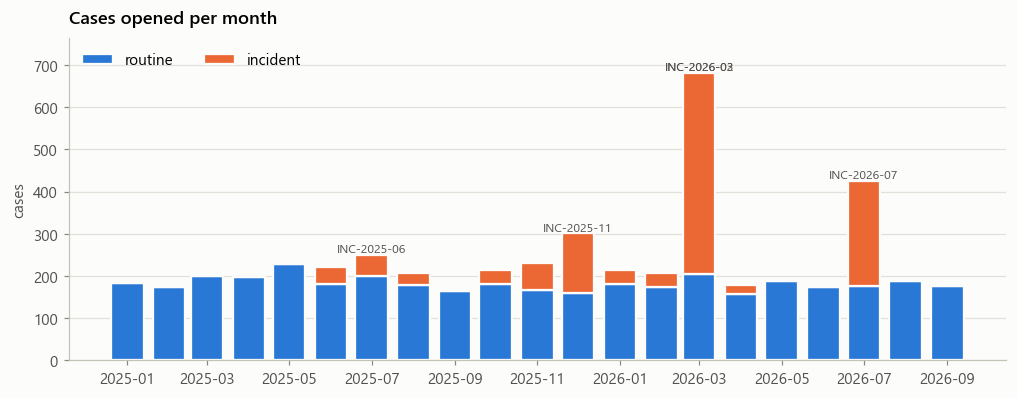

In [5]:
monthly = df.groupby(["month", "is_incident"]).size().unstack(fill_value=0)
# Label each incident once, above its busiest month
peak_month = (df[df.is_incident].groupby(["incident_id", "month"]).size()
              .groupby("incident_id").idxmax().map(lambda t: t[1]))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(monthly.index, monthly[False], width=24, color=BLUE, label="routine", edgecolor=SURFACE, linewidth=1.5)
ax.bar(monthly.index, monthly[True], bottom=monthly[False], width=24, color=ORANGE, label="incident",
       edgecolor=SURFACE, linewidth=1.5)
for iid, m in peak_month.items():
    ax.text(m, monthly.loc[m].sum() + 6, iid, ha="center", fontsize=8, color=INK2)
ax.set_title("Cases opened per month")
ax.set_ylabel("cases")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
ax.margins(y=0.12)
plt.show()

## 3. What customers contact the bank about

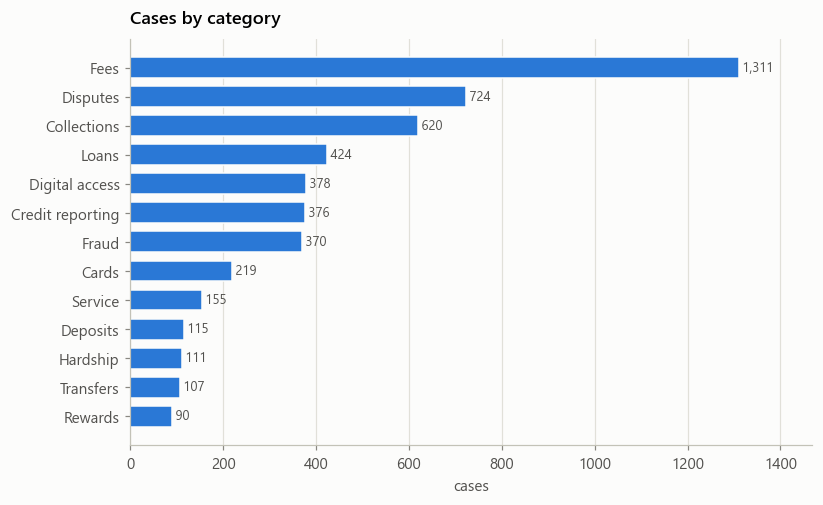

In [6]:
barh(df["category"].value_counts(), "Cases by category")
plt.show()

In [7]:
issues = (df.groupby(["category", "issue"])
            .agg(cases=("case_id", "size"), incident_share=("is_incident", "mean"))
            .sort_values("cases", ascending=False))
issues["incident_share"] = issues["incident_share"].map("{:.0%}".format)
print(f"{len(issues)} distinct issues")
issues.head(20)

51 distinct issues


cases incident_share
category         issue                                                
Disputes         Duplicate charge                   450           100%
Digital access   App lockout                        250           100%
Credit reporting Incorrect information on report    244             0%
Fees             Overdraft fee                      226             0%
Collections      Third-party collector conduct      200           100%
Fees             Monthly maintenance fee            200             0%
                 Card late fee                      175             0%
Collections      Collection contact practices       153             0%
Fees             Late fee - delayed statement       150           100%
Fraud            Unauthorized debit transaction     146             0%
Collections      Debt validation                    138             0%
Credit reporting Goodwill request                   132             0%
Digital access   Sign-in problem                    128             0%
Fraud            Unauthorized credit card charge    126             0%
Loans            Escrow increase                    120           100%
Cards            Lost card replacement              119             0%
Loans            Loan late fee                      113             0%
Hardship         Hardship assistance                111             0%
Transfers        QuickSend to wrong recipient       107             0%
Disputes         Charged after cancellation         103             0%

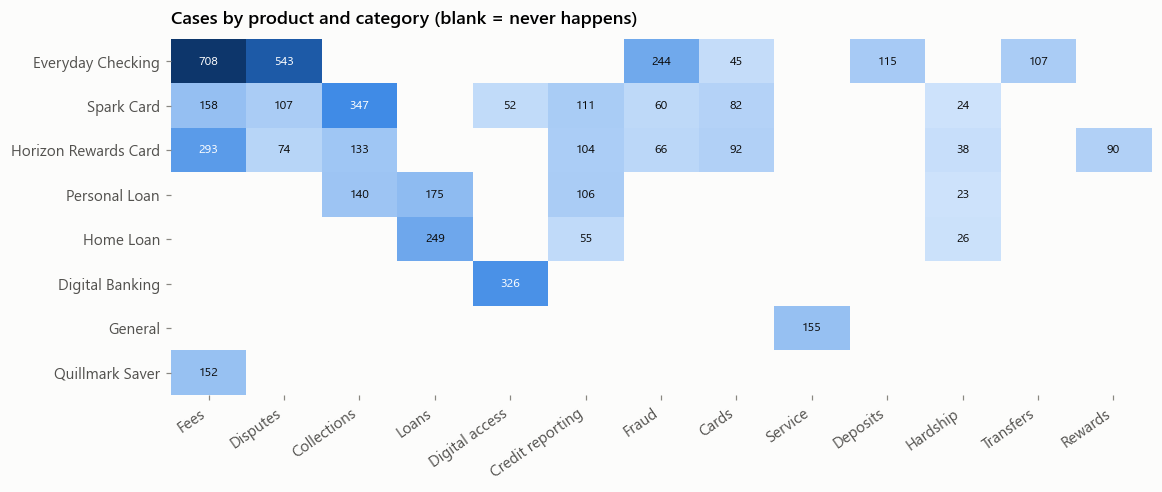

In [8]:
ct = pd.crosstab(df["product"], df["category"])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index, ct.sum().sort_values(ascending=False).index]
vals = ct.values.astype(float)

fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.imshow(np.where(vals == 0, np.nan, vals), cmap=LinearSegmentedColormap.from_list("seq", SEQ), aspect="auto")
ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=35, ha="right")
ax.set_yticks(range(ct.shape[0]), ct.index)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = int(vals[i, j])
        if v:
            ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8,
                    color="white" if v > vals.max() * 0.4 else INK)
ax.set_title("Cases by product and category (blank = never happens)")
plt.show()

## 4. Channels, branches and tone

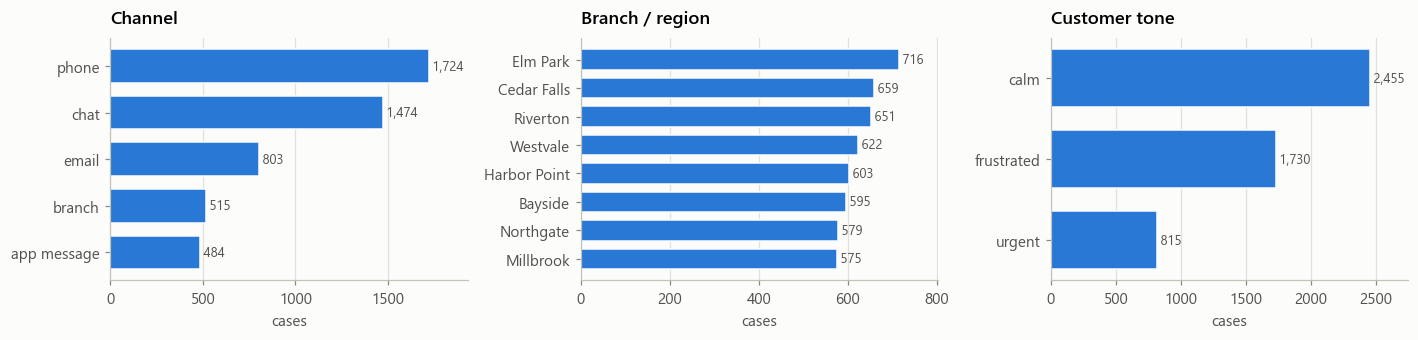

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
barh(df["channel"].value_counts(), "Channel", ax=axes[0])
barh(df["branch"].value_counts(), "Branch / region", ax=axes[1])
barh(df["customer_tone"].value_counts(), "Customer tone", ax=axes[2])
plt.tight_layout()
plt.show()

In [10]:
# Some incidents are local: which branches do incident cases come from?
pd.crosstab(df["branch"], df["incident_id"].fillna("(routine)"), margins=True, margins_name="total")

incident_id,(routine),INC-2025-06,INC-2025-11,INC-2026-02,INC-2026-03,INC-2026-07,total
branch,,,,,,,
Bayside,471,0,0,30,57,37,595
Cedar Falls,463,0,79,23,65,29,659
Elm Park,478,120,0,30,58,30,716
Harbor Point,488,0,0,31,61,23,603
Millbrook,482,0,0,17,45,31,575
Northgate,463,0,0,27,52,37,579
Riverton,469,0,71,25,57,29,651
Westvale,516,0,0,17,55,34,622
total,3830,120,150,200,450,250,5000


## 5. Outcomes and satisfaction

`outcome` says whether the customer got what they asked for. `info` means the customer only asked a question.

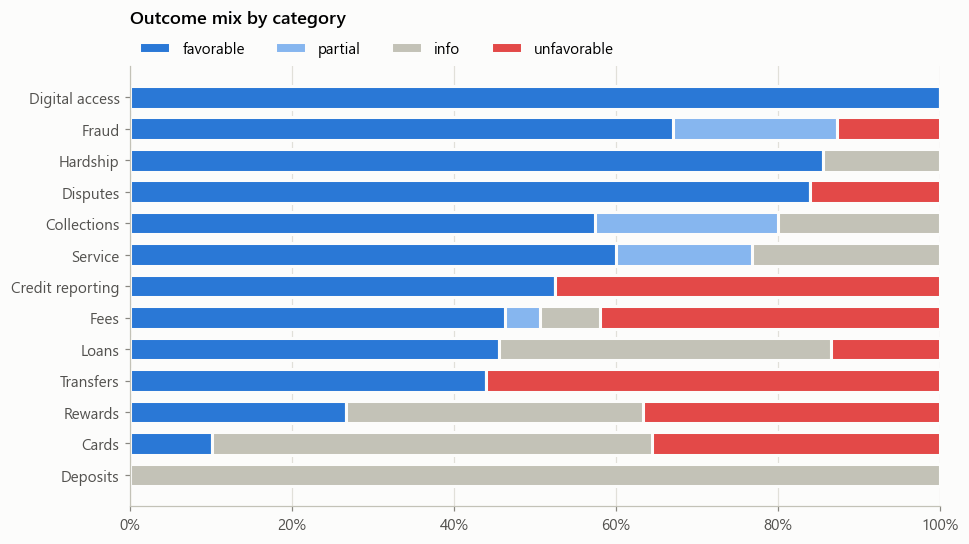

In [11]:
oc = pd.crosstab(df["category"], df["outcome"], normalize="index")[OUTCOME_ORDER]
oc = oc.loc[(oc["favorable"] + oc["partial"]).sort_values().index]

fig, ax = plt.subplots(figsize=(9.5, 5.2))
left = np.zeros(len(oc))
for col in OUTCOME_ORDER:
    ax.barh(oc.index, oc[col], left=left, color=OUTCOME_COLORS[col], label=col,
            height=0.72, edgecolor=SURFACE, linewidth=2)
    left += oc[col].values
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.set_title("Outcome mix by category", pad=28)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2)
ax.set_xlim(0, 1)
plt.show()

In [12]:
sat = pd.crosstab(df["outcome"], df["satisfaction"]).loc[OUTCOME_ORDER]
sat["cases"] = sat.sum(axis=1)
sat["mean satisfaction"] = df.groupby("outcome")["satisfaction"].mean().loc[OUTCOME_ORDER].round(2)
sat

satisfaction,1,2,3,4,5,cases,mean satisfaction
outcome,,,,,,,
favorable,0,0,0,1420,1447,2867,4.50
partial,0,105,94,99,0,298,2.98
info,0,0,242,235,237,714,3.99
unfavorable,357,364,400,0,0,1121,2.04


In [13]:
pd.concat({
    "mean satisfaction": df.groupby(["is_incident", "customer_tone"])["satisfaction"].mean().unstack().round(2),
    "outcome = unfavorable": df.assign(u=df.outcome.eq("unfavorable")).groupby(["is_incident", "customer_tone"])["u"].mean().unstack().round(2),
}, axis=1).rename(index={False: "routine", True: "incident"})

mean satisfaction                   outcome = unfavorable                  
customer_tone              calm frustrated urgent                  calm frustrated urgent
is_incident                                                                              
routine                    3.62       3.66   3.56                  0.29       0.28   0.31
incident                   4.30       4.34   4.29                  0.00       0.00   0.00

## 6. Refunds and time to close

1,826 cases (37%) refunded $657,742.30 in total


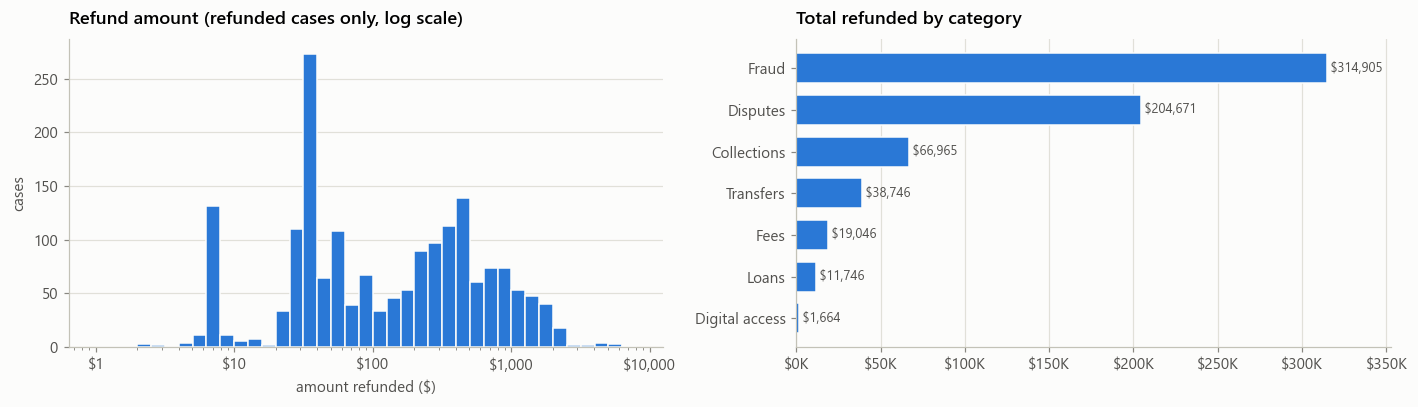

In [14]:
refunded = df[df["amount_refunded"] > 0]
print(f"{len(refunded):,} cases ({len(refunded)/len(df):.0%}) refunded ${refunded.amount_refunded.sum():,.2f} in total")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(refunded["amount_refunded"], bins=np.logspace(0, np.log10(refunded.amount_refunded.max()), 40),
             color=BLUE, edgecolor=SURFACE, linewidth=1)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[0].set_title("Refund amount (refunded cases only, log scale)")
axes[0].set_xlabel("amount refunded ($)")
axes[0].set_ylabel("cases")
axes[0].grid(axis="x", visible=False)
barh(df.groupby("category")["amount_refunded"].sum().loc[lambda s: s > 0],
     "Total refunded by category", xlabel="", ax=axes[1], fmt="${:,.0f}")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
plt.tight_layout()
plt.show()

In [15]:
refunds_by_resolution = (refunded.groupby("resolution")["amount_refunded"]
                         .agg(cases="size", median="median", total="sum")
                         .sort_values("total", ascending=False))
refunds_by_resolution.head(12).round(2)

,cases,median,total
resolution,,,
Charges removed,126,1190.68,146489.76
Dispute won - credit made permanent,158,466.00,76750.63
Reimbursed,51,1501.39,70276.15
Debt not validated - collection stopped,14,4532.74,64740.20
Duplicate reversed; goodwill credit,202,292.79,56655.66
Full credit issued,71,723.21,50729.85
Duplicate reversed; fees refunded; goodwill credit,131,311.19,41270.50
Credit issued minus $50 liability,52,789.98,39908.10
Funds recovered,47,734.14,38745.75


In [16]:
days = df.groupby("category")["days_open"].describe(percentiles=[0.5, 0.9])[["mean", "50%", "90%", "max"]]
days.sort_values("50%", ascending=False).round(1)

,mean,50%,90%,max
category,,,,
Disputes,14.1,9.0,38.0,45.0
Fraud,5.5,5.5,10.0,12.0
Collections,4.8,5.0,10.0,12.0
Digital access,5.4,5.0,9.0,10.0
Credit reporting,4.1,4.0,8.0,10.0
Service,4.6,4.0,9.0,12.0
Transfers,3.9,4.0,8.0,10.0
Hardship,4.8,4.0,10.0,10.0
Fees,3.9,3.0,9.0,12.0


## 7. Policies (the CAG source)

Parse the handbook into one row per policy, then join each policy to the cases that cite it.

In [17]:
area, records = None, []
for block in re.split(r"\n(?=## |### )", handbook):
    if block.startswith("### "):
        m = re.match(r"### \[(POL-[A-Z]+-\d+)\] (.+?)\n\n(.*)", block, re.S)
        records.append({"policy_id": m[1], "area": area, "title": m[2], "body": m[3].strip()})
    elif block.startswith("## "):
        area = block[3:].splitlines()[0].strip()

policies = pd.DataFrame(records).set_index("policy_id")
policies["words"] = policies["body"].str.split().str.len()
policies["tokens"] = policies["body"].apply(n_tokens)

print(f"{len(policies)} policies in {policies.area.nunique()} areas")
print(f"Handbook: {len(handbook):,} chars, ~{n_tokens(handbook):,} tokens")
print(f"Per policy: {policies.tokens.min()}-{policies.tokens.max()} tokens, mean {policies.tokens.mean():.0f}")

32 policies in 8 areas
Handbook: 18,097 chars, ~4,020 tokens
Per policy: 74-163 tokens, mean 110


Policies never cited: ['POL-CRD-03', 'POL-COL-01']


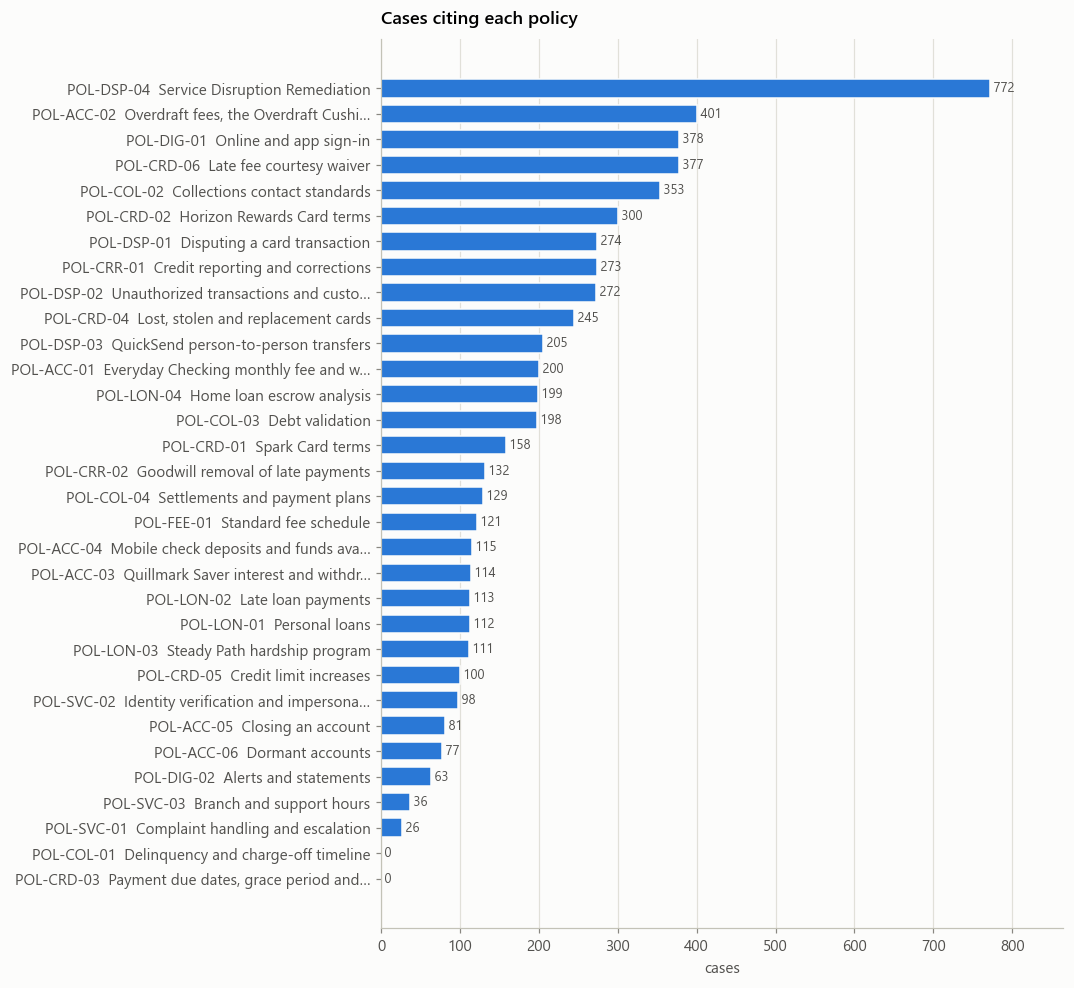

In [18]:
cites = df.explode("related_policies").dropna(subset=["related_policies"])
by_policy = cites.groupby("related_policies").agg(
    cases=("case_id", "size"),
    favorable=("outcome", lambda s: (s == "favorable").mean()),
    incident_share=("is_incident", "mean"),
    top_issue=("issue", lambda s: s.mode()[0]),
)
policies = policies.join(by_policy)
policies["cases"] = policies["cases"].fillna(0).astype(int)
print("Policies never cited:", policies.index[policies.cases == 0].tolist() or "none")

short = policies["title"].where(policies["title"].str.len() <= 36, policies["title"].str.slice(0, 35) + "…")
labels = policies.index + "  " + short
barh(pd.Series(policies["cases"].values, index=labels), "Cases citing each policy")
plt.show()

In [19]:
view = policies[["area", "title", "tokens", "cases", "favorable", "incident_share", "top_issue"]].copy()
view["favorable"] = view["favorable"].map("{:.0%}".format)
view["incident_share"] = view["incident_share"].map("{:.0%}".format)
view.sort_values("cases", ascending=False)

,area,title,tokens,cases,favorable,incident_share,top_issue
policy_id,,,,,,,
POL-DSP-04,Disputes and fraud,Service Disruption Remediation,145,772,100%,100%,Duplicate charge
POL-ACC-02,Accounts,"Overdraft fees, the Overdraft Cushion and the Fix-It Window",139,401,74%,44%,Overdraft fee
POL-DIG-01,Digital banking,Online and app sign-in,91,378,100%,66%,App lockout
POL-CRD-06,Cards,Late fee courtesy waiver,101,377,80%,54%,Card late fee
POL-COL-02,Collections,Collections contact standards,112,353,60%,57%,Third-party collector conduct
POL-CRD-02,Cards,Horizon Rewards Card terms,163,300,34%,0%,Card late fee
POL-DSP-01,Disputes and fraud,Disputing a card transaction,125,274,58%,0%,Charged after cancellation
POL-CRR-01,Credit reporting,Credit reporting and corrections,104,273,66%,11%,Incorrect information on report
POL-DSP-02,Disputes and fraud,Unauthorized transactions and customer liability,100,272,72%,0%,Unauthorized debit transaction


In [20]:
print("Policies cited per case:")
print(df["n_policies"].value_counts().sort_index().to_string())

print("\nCases citing no policy, by issue:")
print(df.loc[df.n_policies == 0, "issue"].value_counts().to_string())

pairs = Counter(p for rp in df["related_policies"] for p in combinations(sorted(rp), 2))
pd.DataFrame(pairs.most_common(10), columns=["policy pair", "cases"])

Policies cited per case:
n_policies
0      93
1    3862
2     964
3      81

Cases citing no policy, by issue:
issue
Card activation    37
Order checks       30
Address change     26


,policy pair,cases
0,"(POL-CRD-06, POL-DSP-04)",202
1,"(POL-ACC-02, POL-DSP-04)",175
2,"(POL-CRD-04, POL-DSP-02)",126
3,"(POL-DSP-04, POL-LON-04)",120
4,"(POL-DSP-03, POL-SVC-02)",98
5,"(POL-CRD-01, POL-CRD-06)",91
6,"(POL-CRD-02, POL-CRD-06)",84
7,"(POL-CRD-01, POL-CRD-02)",67
8,"(POL-COL-02, POL-COL-03)",60
9,"(POL-CRD-06, POL-DIG-01)",52


## 8. Incidents

There is no incidents file: incidents exist only as `incident_id` on cases and as explanations in the agent notes. Rebuild the table here.

In [21]:
inc = df[df.is_incident]
incidents = inc.groupby("incident_id").agg(
    cases=("case_id", "size"),
    first_opened=("opened_date", "min"),
    last_opened=("opened_date", "max"),
    issue=("issue", lambda s: ", ".join(s.unique())),
    product=("product", lambda s: ", ".join(s.value_counts().index)),
    branches=("branch", "nunique"),
    refunded=("amount_refunded", "sum"),
    policies=("related_policies", lambda s: ", ".join(sorted({p for rp in s for p in rp}))),
    unfavorable=("outcome", lambda s: int((s == "unfavorable").sum())),
)
incidents["days_active"] = (incidents.last_opened - incidents.first_opened).dt.days + 1
incidents

,cases,first_opened,last_opened,issue,product,branches,refunded,policies,unfavorable,days_active
incident_id,,,,,,,,,,
INC-2025-06,120,2025-06-03,2025-08-14,Escrow increase,Home Loan,1,4899.0,"POL-DSP-04, POL-LON-04",0,73
INC-2025-11,150,2025-11-20,2025-12-31,Late fee - delayed statement,Horizon Rewards Card,2,6156.0,"POL-CRD-06, POL-CRR-01, POL-DSP-04",0,42
INC-2026-02,200,2025-10-01,2026-03-31,Third-party collector conduct,Spark Card,8,2225.0,"POL-COL-02, POL-COL-03",0,182
INC-2026-03,450,2026-03-14,2026-04-10,Duplicate charge,Everyday Checking,8,127920.6,"POL-ACC-02, POL-DSP-04",0,28
INC-2026-07,250,2026-07-08,2026-07-30,App lockout,"Digital Banking, Spark Card",8,1664.0,"POL-CRD-06, POL-DIG-01, POL-DSP-04",0,23


In [22]:
# Is the tagging complete? Share of each incident issue's cases that carry an incident_id
inc_issues = incidents["issue"].str.split(", ").explode().unique()
df[df.issue.isin(inc_issues)].groupby("issue")["is_incident"].agg(cases="size", tagged="mean")

,cases,tagged
issue,,
App lockout,250,1.0
Duplicate charge,450,1.0
Escrow increase,120,1.0
Late fee - delayed statement,150,1.0
Third-party collector conduct,200,1.0


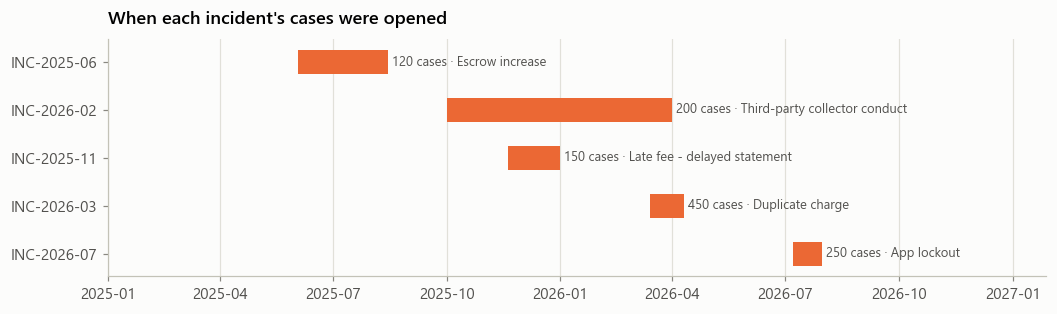

In [23]:
fig, ax = plt.subplots(figsize=(11, 2.8))
order = incidents.sort_values("first_opened")
for y, (iid, r) in enumerate(order.iterrows()):
    ax.barh(y, (r.last_opened - r.first_opened).days + 1, left=r.first_opened, height=0.5, color=ORANGE)
    ax.text(r.last_opened + pd.Timedelta(days=4), y, f"{r.cases} cases · {r.issue}", va="center",
            fontsize=8.5, color=INK2)
ax.set_yticks(range(len(order)), order.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlim(df.opened_date.min(), df.opened_date.max() + pd.Timedelta(days=120))
ax.set_title("When each incident's cases were opened")
plt.show()

In [24]:
# One agent note per incident: this is the only place the root cause is written down
for iid, g in inc.groupby("incident_id"):
    print(f"{iid}: {g.agent_notes.iloc[0]}\n")

INC-2025-06: Elm Park escrow re-analyses run in June 2025 used prior-year assessment data from the tax data vendor, overstating property taxes. Logged under INC-2025-06. Advised customer not to pay the shortage; a corrected escrow analysis will be mailed.

INC-2025-11: Customer in Riverton affected by INC-2025-11: November-cycle Horizon paper statements for Riverton and Cedar Falls were mailed 9 days late by print vendor Ashgrove Print Services. Late fee $32 reversed under POL-DSP-04; this reversal does not count toward the courtesy waiver (POL-CRD-06). Offered a free switch to e-statements.

INC-2026-02: Spark charged-off account placed with third-party agency Brightway Recovery Partners (agency placement, September 2025). Repeated calls to the customer's workplace violate the employer-contact rule (POL-COL-02). Logged conduct complaint under INC-2026-02 and forwarded to vendor management. Instructed agency to stop all workplace calls.

INC-2026-03: Confirmed duplicate posting caused 

## 9. Text for retrieval (the RAG source)

How long each case is, whether the corpus fits in a context window, and how templated the text is.

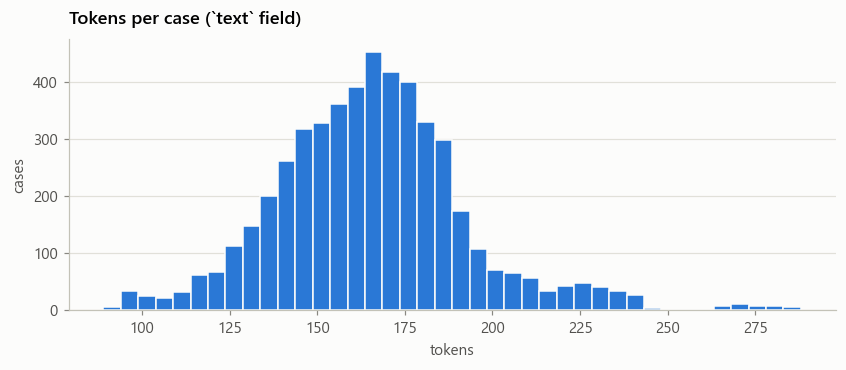

,value
handbook tokens,4020
"case tokens, mean",166
"case tokens, max",288
"all cases, tokens",827870
all cases vs 32K context,26x too big
all cases vs 128K context,6x too big
handbook share of 16K context,25%


In [25]:
df["text_tokens"] = df["text"].apply(n_tokens)
total_case_tokens = int(df["text_tokens"].sum())
handbook_tokens = n_tokens(handbook)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(df["text_tokens"], bins=40, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.set_title("Tokens per case (`text` field)")
ax.set_xlabel("tokens")
ax.set_ylabel("cases")
ax.grid(axis="x", visible=False)
plt.show()

pd.Series({
    "handbook tokens": handbook_tokens,
    "case tokens, mean": round(df.text_tokens.mean()),
    "case tokens, max": df.text_tokens.max(),
    "all cases, tokens": total_case_tokens,
    "all cases vs 32K context": f"{total_case_tokens / 32_000:.0f}x too big",
    "all cases vs 128K context": f"{total_case_tokens / 128_000:.0f}x too big",
    "handbook share of 16K context": f"{handbook_tokens / 16_000:.0%}",
}, name="value").to_frame()

In [26]:
normalize = lambda s: re.sub(r"\d[\d,.]*", "#", s)
templating = pd.DataFrame({
    "unique raw": [df.customer_narrative.nunique(), df.agent_notes.nunique()],
    "unique with numbers masked": [df.customer_narrative.map(normalize).nunique(),
                                    df.agent_notes.map(normalize).nunique()],
}, index=["customer_narrative", "agent_notes"])
templating["share of 5,000"] = (templating["unique with numbers masked"] / len(df)).map("{:.0%}".format)
templating

,unique raw,unique with numbers masked,"share of 5,000"
customer_narrative,4752,4394,88%
agent_notes,2278,139,3%


In [27]:
# Most repeated agent-note templates (numbers masked)
df["notes_template"] = df["agent_notes"].map(normalize)
df["notes_template"].value_counts().head(8).to_frame("cases")

,cases
notes_template,
INC-#-#: app version # (released #/#/#) locked accounts after a single failed sign-in and rejected valid one-time codes. Fixed in version # released #/#/# Unlocked account via phone verification and advised the customer to update the app.,198
"Dispute filed # days after the statement date, within the #-day window (POL-DSP-#). Provisional credit of $# issued within # business days. Investigation closed in the customer's favor; credit made permanent.",131
Unauthorized credit card use: $# cardholder liability (POL-DSP-#). Charges of $# removed; card replaced and digital card number issued in the app (POL-CRD-#).,126
Confirmed duplicate posting caused by the INC-#-# card processing outage (#/#/# #:# p.m. to #/#/# #:# a.m.). Duplicate $# reversed automatically on #/#/# Issued $# goodwill credit for the disruption.,114
"Validation requested # days after the first collection notice (within # days, POL-COL-#). Collection paused. Validation letter sent #/#/# with original account ending # charge-off date, balance and itemized fees. Collection resumed after the letter.",111
"No other late payments in the prior # months and past-due amount paid. One-time courtesy waiver granted (POL-CRD-#). $# late fee reversed. Payment was under # days late, so it was not reported to Meridian Credit Registry.",99
Investigation completed in # days (POL-CRR-#). Records show the reported information is accurate (payment received after the due date / balance as of statement date). Reporting upheld.,93
Confirmed duplicate posting caused by the INC-#-# card processing outage (#/#/# #:# p.m. to #/#/# #:# a.m.). Duplicate $# will be reversed automatically; expected completion #/#/# Issued $# goodwill credit for the disruption.,88


In [28]:
mentions = pd.Series({
    "text mentions a POL- id": df.text.str.contains(r"POL-[A-Z]+-\d+").mean(),
    "text mentions an INC- id": df.text.str.contains(r"INC-\d{4}-\d{2}").mean(),
    "text mentions a $ amount": df.customer_narrative.str.contains(r"\$\d").mean(),
}).map("{:.0%}".format)
mentions.to_frame("share of cases")

,share of cases
text mentions a POL- id,86%
text mentions an INC- id,23%
text mentions a $ amount,64%


## 10. The `meta` field

Case-specific numbers (months on time, days late, etc.). Keys depend on the issue, so `meta` is sparse.

In [29]:
meta_keys = (df.assign(key=df["meta"].apply(list)).explode("key").dropna(subset=["key"])
               .groupby("key").agg(cases=("case_id", "size"), issues=("issue", lambda s: ", ".join(s.unique()[:4]))))
meta_keys.sort_values("cases", ascending=False)

,cases,issues
key,,
variant,876,"Monthly maintenance fee, Overdraft fee, Third-party collector conduct, App lockout"
goodwill,582,"Goodwill request, Duplicate charge"
overdraft,450,Duplicate charge
third_party,450,Duplicate charge
days_after_statement,274,"Incorrect amount, Item not received, Charged after cancellation"
foreign,226,"Incorrect amount, Item not received, Charged after cancellation"
waiver,175,Card late fee
reason,162,"Goodwill request, Card late fee"
reported,150,Late fee - delayed statement


## 11. Takeaways for the pipeline

**Data quality**
- Clean: unique case IDs, no nulls outside `incident_id`, no negative durations, and the policy IDs in `agent_notes` always match `related_policies`.
- `text` already contains every field the chatbot needs, so it's the document to embed.

**CAG: the handbook**
- 32 policies, about 4K tokens. That's about 25% of a 16K context, so the whole handbook can live in a cached prefix.
- Policies are short (74–163 tokens), and one `### [POL-…]` block is a natural unit if you also build a RAG baseline to compare against.
- 2 policies are never cited by a case (POL-CRD-03 due dates and grace period, POL-COL-01 delinquency timeline). The chatbot can only answer about them from the handbook, which makes them good CAG test questions.

**RAG: the cases**
- About 830K tokens in total, 6x too big even for a 128K context, so retrieval is required. Cases are 166 tokens on average (max 288), so one case = one chunk.
- Agent notes are heavily templated: only 139 distinct templates once numbers are masked. Top-k search will often return near-identical cases, so use MMR or deduplicate by template to keep results diverse.
- Exact IDs matter: 86% of cases mention a POL- ID and 23% an INC- ID. Use hybrid search (BM25 + vectors).

**Structured questions: use SQL, not embeddings**
- 8 branches, 8 products, 13 categories, 51 issues, 5 channels and 4 outcomes are clean, low-cardinality fields. They work as metadata filters and for counting questions.
- Money and timing questions (refunds: $658K across 1,826 cases; days to close) are aggregates. Answer them from DuckDB.

**Incidents**
- 5 incidents and 1,170 cases. The tagging is complete: every case of each incident issue is tagged. Incident cases never end unfavorably.
- There is no incidents table. Build one from this notebook's section 8 and add each incident's root cause from its agent notes.
- An incident ID gives the month the incident was logged, not when it started. INC-2026-02 cases run from Oct 2025 to Mar 2026.
- Some incidents are local: INC-2025-06 is Elm Park only, and INC-2025-11 is Riverton and Cedar Falls only. Branch and date filters help decide whether a new complaint belongs to an incident.

**Evaluation data**
- `customer_narrative` → `related_policies` / `resolution` / `outcome` gives about 4,900 labelled examples for free (93 cases have no policy).
- The outcome is a strong label: satisfaction ranges are separated by outcome (favorable 4–5, unfavorable 1–3).